In this notebook we reproduce the plots of arXiv:2604.09797 from the raw data points. We do not include any code that allows you to generate the circuits that were simulated, these can be found in `Example_notebook`. This notebook is ordered chronologically in the order that I personally ran them, not in the order that it appears in arXiv:2604.09797, sorry.

There are a few packages (`scipy`, `matplotlib`, `cycler`) that are used here that are not required by `morphing_qec_circuits`, so only run this if you have these packages installed.

In [1]:
#importations
from copy import deepcopy
import numpy as np
from scipy.stats import norm
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from cycler import cycler
import pickle

mpl.rcParams.update({"text.usetex": True,
                     'font.size': 10,
                    'mathtext.fontset': 'stix',
                    'font.family': 'STIXGeneral'})
                     #'axes.linewidth': 2,

In [2]:
def shots_to_pl(n_flips, n_shots, confidence = 0.99, T_for_scale = 1, num_copies = 1):
    #T_for_scale = 1 does NOT scale for number of rounds.
    #To scale for number of rounds put T_for_scale to the number of rounds.
    if n_shots == 0:
        return 0, 0, 0
    alpha = 1 - confidence
    z = norm.ppf(1 - alpha / 2)

    average = n_flips/n_shots
    middle = (n_flips + z**2/2) / (n_shots + z**2)
    diff = z/(n_shots+z**2) * np.sqrt(n_flips * (n_shots-n_flips)/n_shots + z**2/4)
    lower_p = (middle - diff)
    upper_p = middle+diff
    average = 1-(1-average)**(1/T_for_scale)
    lower_p = 1-(1-lower_p)**(1/T_for_scale)
    upper_p = 1-(1-upper_p)**(1/T_for_scale)
    average = 1-(1-average)**(num_copies)
    lower_p = 1-(1-lower_p)**(num_copies)
    upper_p = 1-(1-upper_p)**(num_copies)
    lower_bar = max(0,average - lower_p)
    upper_bar = max(0,upper_p - average)
    return average, lower_bar, upper_bar

## Figure 23(c)

In [3]:
with open("used_data/1A.pkl", "rb") as f:
    raw_data = pickle.load(f)

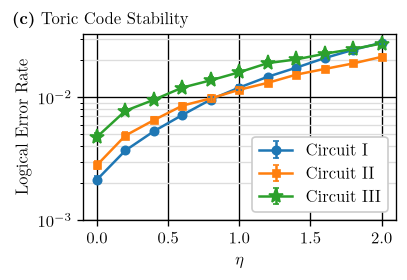

In [4]:
ps = np.array([0.002,0.001,0.0005])
xs = np.array([0.0,0.2,0.4,0.6,0.8,1.0,1.2,1.4,1.6,1.8,2.0])
pls = np.zeros((3,len(ps),len(xs)))
lbs = np.zeros((3,len(ps),len(xs)))
ubs = np.zeros((3,len(ps),len(xs)))

for data_point in raw_data:
    i = np.argmin(np.abs(ps - 10**data_point["log_p"]))
    j = np.argmin(np.abs(xs - data_point["x"]))
    for k in range(3):
        pls[k,i,j], lbs[k,i,j], ubs[k,i,j] = shots_to_pl(data_point["flips"][k], data_point["shots"][k])

empirical_width = 3.45
target_width = 3.40

fig, ax = plt.subplots(1, 1, figsize=(3.41666666667 * target_width/empirical_width,3.478984 * target_width/empirical_width/1.7))
symbols = ['o','s','*','^','X']
sizes = [5, 4.2, 9.1, 5, 5]
legend_sizes = [4,3.5,6,5,4.5]

i = 0
formal_labels = {"standard": "Circuit I", "scrambled": "Circuit II", "hex_scrambled": "Circuit III"}

for k in range(3):
    ax.errorbar(xs, pls[k,i,:], yerr = [lbs[k,i,:], ubs[k,i,:]],
                        label = formal_labels[raw_data[0]["labels"][k]], linestyle = "-", marker = symbols[k], ms=sizes[k], capsize=2, barsabove = True)

ax.set_ylim(1e-3, 3.3e-2)
#ax.set_xlim(0, 700)
#ax.set_xscale('log')
ax.set_yscale('log')
#fig.suptitle("d=4, T=5 surface code stability experiment, SI1000, belief matching")
#ax.set_title(f"p={ps[i]}")
ax.set_xlabel(r"$\eta$")
ax.set_ylabel("Logical Error Rate")
ax.grid(which='major', color='#000000')
ax.grid(which='minor', color='#DDDDDD')
ax.yaxis.set_minor_formatter(plt.NullFormatter())
fig.text(-0.05, 0.92, r'\textbf{(c)} Toric Code Stability')
ax.legend(bbox_to_anchor = (1,0), loc = "lower right", framealpha=1)
fig.set_dpi(120)  # Show it bigger

## Figure 23(a) and 23(b)

In [5]:
with open("used_data/1D.pkl", "rb") as f:
    raw_data = pickle.load(f)
    
xs = np.array([0.0,0.4,1.0,1.5,2.0])
pls = np.zeros((4,len(xs)))
lbs = np.zeros((4,len(xs)))
ubs = np.zeros((4,len(xs)))

for data_point in raw_data:
    i = np.argmin(np.abs(xs - data_point["x"]))
    for k in range(4):
        pls[k,i], lbs[k,i], ubs[k,i] = shots_to_pl(data_point["flips"][k], data_point["shots"][k])

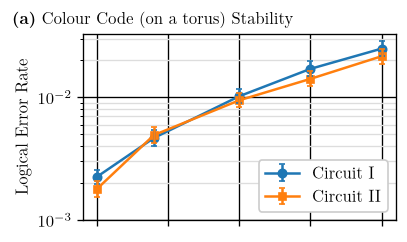

In [6]:
empirical_width = 3.45# set this first to the target_width, check the pdf, then come back with the actual width.
target_width = 3.40

fig, ax = plt.subplots(1, 1, figsize=(3.41666666667 * target_width/empirical_width,3.478984 * target_width/empirical_width/1.7))
symbols = ['o','s','*','^','X']
sizes = [5, 4.2, 9.1, 6, 5]
legend_sizes = [4,3.5,6,5.1,4.5]

formal_labels = {"simple_det": "Circuit I",
                 "non_simple_det": "Circuit II",
                }

for k in range(2):
    ax.errorbar(xs, pls[k,:], yerr = [lbs[k,:], ubs[k,:]],
                        label = formal_labels[raw_data[0]["labels"][k]], linestyle = "-", marker = symbols[k], ms=sizes[k], capsize=2, barsabove = True)

ax.set_ylim(1e-3, 3.3e-2)
#ax.set_xlim(0, 700)
#ax.set_xscale('log')
ax.set_yscale('log')
#fig.suptitle("d=4, T=5 surface code stability experiment, SI1000, belief matching")
#ax.set_title(f"p={ps[i]}")
#ax.set_xlabel(r"Measurement Error Rate Scaling Factor ($\eta$)")
ax.set_xticklabels([])
ax.set_ylabel("Logical Error Rate")
ax.grid(which='major', color='#000000')
ax.grid(which='minor', color='#DDDDDD')
ax.yaxis.set_minor_formatter(plt.NullFormatter())
fig.text(-0.05, 0.92, r'\textbf{(a)} Colour Code (on a torus) Stability')
ax.legend(bbox_to_anchor = (1,0), loc = "lower right", framealpha=1)
fig.set_dpi(120)  # Show it bigger

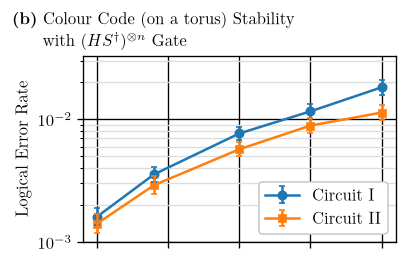

In [7]:
empirical_width = 3.45# set this first to the target_width, check the pdf, then come back with the actual width.
target_width = 3.40

fig, ax = plt.subplots(1, 1, figsize=(3.41666666667 * target_width/empirical_width,3.478984 * target_width/empirical_width/1.7))
symbols = ['o','s','*','^','X']
sizes = [5, 4.2, 9.1, 6, 5]
legend_sizes = [4,3.5,6,5.1,4.5]

formal_labels = {
                 "simple_det_with_gate": "Circuit I",
                 "non_simple_det_with_gate": "Circuit II",
                }

for k in range(2,4):
    ax.errorbar(xs, pls[k,:], yerr = [lbs[k,:], ubs[k,:]],
                        label = formal_labels[raw_data[0]["labels"][k]], linestyle = "-", marker = symbols[k-2], ms=sizes[k-2], capsize=2, barsabove = True)

ax.set_ylim(1e-3, 3.3e-2)
#ax.set_xlim(0, 700)
#ax.set_xscale('log')
ax.set_yscale('log')
#fig.suptitle("d=4, T=5 surface code stability experiment, SI1000, belief matching")
#ax.set_title(f"p={ps[i]}")
#ax.set_xlabel(r"Measurement Error Rate Scaling Factor ($\eta$)")
ax.set_xticklabels([])
ax.set_ylabel("Logical Error Rate")
ax.grid(which='major', color='#000000')
ax.grid(which='minor', color='#DDDDDD')
ax.yaxis.set_minor_formatter(plt.NullFormatter())
fig.text(-0.05, 1.01, r'\textbf{(b)} Colour Code (on a torus) Stability')
fig.text(0.026, 0.92, r'with $(HS^{\dag})^{\otimes n}$ Gate')
ax.legend(bbox_to_anchor = (1,0), loc = "lower right", framealpha=1)
fig.set_dpi(120)  # Show it bigger

## Figure 31

In [8]:
with open("used_data/2A.pkl", "rb") as f:
    raw_data = pickle.load(f)

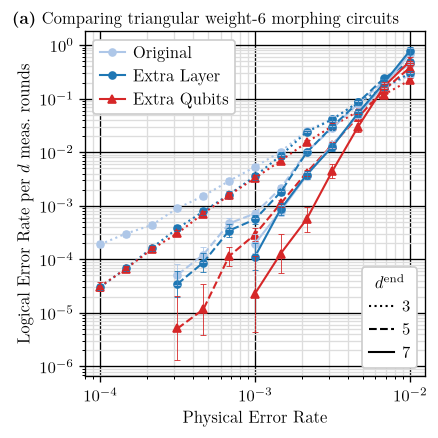

In [9]:
ps = 10**np.linspace(-4,-2,13)
ds = np.array([3, 5, 7])
circuits = ["morphing", "morphing_extra_layer", "morphing_extra_qubits"]
pls = np.zeros((len(circuits),len(ps),len(ds)))
lbs = np.zeros((len(circuits),len(ps),len(ds)))
ubs = np.zeros((len(circuits),len(ps),len(ds)))

for data_point in raw_data:
    i = np.argmin(np.abs(ps - 10**data_point["log_p"]))
    j = np.argmin(np.abs(ds - data_point["d"]))
    if data_point["label"] in circuits:
        k = circuits.index(data_point["label"])
        pls[k,i,j], lbs[k,i,j], ubs[k,i,j] = shots_to_pl(data_point["flips"], data_point["shots"])

#here, empirical_width and target_width should be for both this cell and the one below (taken as a sum)
empirical_width = 3.43+2.92# set this first to the target_width, check the pdf, then come back with the actual width.
target_width = 6.81

symbols = ['o','s','^','*','v','D']
linestyles = ["-", "--", ":", "-.", (0,(5,1,1,1,1,1))]
sizes = [5/1.2, 4.2/1.2, 6/1.2, 8/1.2, 6/1.2, 4.2/1.2]
legend_sizes = [4,3.5,5.1,6,5.1,3.5]
formal_labels = {"morphing": "Original",
                 "morphing_extra_layer": "Extra Layer",
                 "morphing_extra_qubits": "Extra Qubits",
                }
cmap = plt.get_cmap('tab20')
line_colors = {"morphing": cmap(1),
          "morphing_extra_layer": cmap(0),
          "morphing_extra_qubits": cmap(6),
         }
#(np.array(colors.to_rgb(cmap(1)))+np.array(colors.to_rgb(cmap(2))))/2

fig, ax = plt.subplots(1, 1, figsize=(3.41666666667 * target_width/empirical_width,3.478984 * target_width/empirical_width))

legend1_handles = []
for j in range(len(ds)):
    for i in range(len(circuits)):
        symbol_index = [0,0,2][i]
        k = {0: 0, 1: 3, 2: 6}[j]# this is just because the first 3 "data points" for the d=7 line are empty
        if j == 2:
            error_bar_container = ax.errorbar(ps[k:], pls[i,k:,j], yerr = [lbs[i,k:,j], ubs[i,k:,j]],
                            linestyle = linestyles[len(ds)-1-j],linewidth = 1.25,
                        color = line_colors[circuits[i]],
                            marker = symbols[symbol_index], ms=sizes[symbol_index],elinewidth=0.5, capthick = 0.5, capsize=2, barsabove = True)
            error_bar_container[0].set_label(formal_labels[circuits[i]])
            legend1_handles.append(error_bar_container[0])
        else:
            ax.errorbar(ps[k:], pls[i,k:,j], yerr = [lbs[i,k:,j], ubs[i,k:,j]],
                            linestyle = linestyles[len(ds)-1-j],linewidth = 1.25,
                        color = line_colors[circuits[i]],
                            marker = symbols[symbol_index], ms=sizes[symbol_index],elinewidth=0.5, capthick = 0.5, capsize=2, barsabove = True)
    plt.gca().set_prop_cycle(None)

fig.text(-0.04, 0.897, r'\textbf{(a)} Comparing triangular weight-6 morphing circuits')

ax.set_ylim(6.57491202030194e-07, 1.8022732185048793)
#ax.set_xlim(0, 700)
ax.set_xscale('log')
ax.set_yscale('log')
#ax.set_title("Colour code memory experiment, SI1000 x=1, MLE")
ax.set_xlabel("Physical Error Rate")
ax.set_ylabel(r"Logical Error Rate per $d$ meas.~rounds")
ax.grid(which='major', color='#000000')
ax.grid(which='minor', color='#DDDDDD')
legend1 = ax.legend(handles = legend1_handles, handlelength = 1.5, handletextpad = 0.5, bbox_to_anchor = (0.0,1.0), loc = "upper left", framealpha=1)
ax.add_artist(legend1)
legend2_handles = []
for j in range(len(ds)):
    legend2_handles.append(ax.plot([],[], linestyle = linestyles[len(ds)-1-j],linewidth = 1.25,color = 'k',label=str(ds[j]))[0])
plt.legend(title = r'$d^{\mathrm{end}}$', handlelength = 1.5, handletextpad = 0.5, handles=legend2_handles, loc='lower right', framealpha=1)
fig.set_dpi(120)  # Show it bigger

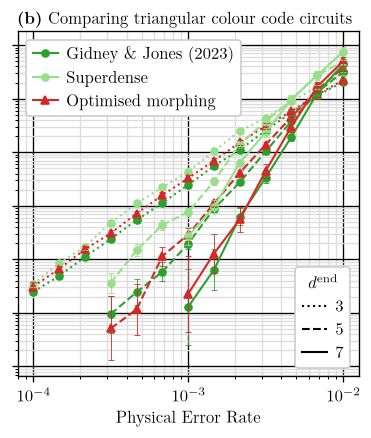

In [10]:
ps = 10**np.linspace(-4,-2,13)
ds = np.array([3, 5, 7])
circuits = ["morphing_Gidney", "superdense", "morphing_extra_qubits"]
pls = np.zeros((len(circuits),len(ps),len(ds)))
lbs = np.zeros((len(circuits),len(ps),len(ds)))
ubs = np.zeros((len(circuits),len(ps),len(ds)))

for data_point in raw_data:
    i = np.argmin(np.abs(ps - 10**data_point["log_p"]))
    j = np.argmin(np.abs(ds - data_point["d"]))
    if data_point["label"] in circuits:
        k = circuits.index(data_point["label"])
        pls[k,i,j], lbs[k,i,j], ubs[k,i,j] = shots_to_pl(data_point["flips"], data_point["shots"])


symbols = ['o','s','^','*','v','D']
linestyles = ["-", "--", ":", "-.", (0,(5,1,1,1,1,1))]
sizes = [5/1.2, 4.2/1.2, 6/1.2, 8/1.2, 6/1.2, 4.2/1.2]
legend_sizes = [4,3.5,5.1,6,5.1,3.5]
formal_labels = {"superdense": "Superdense",
                 "morphing_Gidney": r"Gidney \& Jones~(2023)",
                 "morphing_extra_qubits": "Optimised morphing",
                }
cmap = plt.get_cmap('tab20')
line_colors = {"superdense": cmap(5),
          "morphing_Gidney": cmap(4),
          "morphing_extra_qubits": cmap(6),
         }

fig, ax = plt.subplots(1, 1, figsize=(3.41666666667 * target_width/empirical_width,3.478984 * target_width/empirical_width))

ax = plt.gca()

# Get the current color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Rotate the cycle so it starts from the third color
new_colors = colors[2:] + colors[:2]

legend1_handles = []
for j in range(len(ds)):
    # Set the new cycle
    ax.set_prop_cycle(cycler(color=new_colors))
    for i in range(len(circuits)):
        symbol_index = [0, 0, 2][i]
        k = {0: 0, 1: 3, 2: 6}[j]# this is just because the first 3 "data points" for the d=7 line are empty
        if j == 2:
            error_bar_container = ax.errorbar(ps[k:], pls[i,k:,j], yerr = [lbs[i,k:,j], ubs[i,k:,j]],
                            linestyle = linestyles[len(ds)-1-j],linewidth = 1.25,
                        color = line_colors[circuits[i]],
                            marker = symbols[symbol_index], ms=sizes[symbol_index],elinewidth=0.5, capthick = 0.5, capsize=2, barsabove = True)
            error_bar_container[0].set_label(formal_labels[circuits[i]])
            legend1_handles.append(error_bar_container[0])
        else:
            ax.errorbar(ps[k:], pls[i,k:,j], yerr = [lbs[i,k:,j], ubs[i,k:,j]],
                            linestyle = linestyles[len(ds)-1-j],linewidth = 1.25,
                        color = line_colors[circuits[i]],
                            marker = symbols[symbol_index], ms=sizes[symbol_index],elinewidth=0.5, capthick = 0.5, capsize=2, barsabove = True)

fig.text(0.123, 0.897, r'\textbf{(b)} Comparing triangular colour code circuits')

ax.set_ylim(6.57491202030194e-07, 1.8022732185048793)
#ax.set_xlim(0, 700)
ax.set_xscale('log')
ax.set_yscale('log')
#ax.set_title("Colour code memory experiment, SI1000 x=1, MLE")
ax.set_xlabel("Physical Error Rate")
ax.set_yticklabels([])
#ax.set_ylabel(r"Logical Error Rate per $d$ meas.~rounds")
ax.grid(which='major', color='#000000')
ax.grid(which='minor', color='#DDDDDD')
legend1 = ax.legend(handles = legend1_handles, handlelength = 1.5, handletextpad = 0.5, bbox_to_anchor = (0.0,1.0), loc = "upper left", framealpha=1)
ax.add_artist(legend1)
legend2_handles = []
for j in range(len(ds)):
    legend2_handles.append(ax.plot([],[], linestyle = linestyles[len(ds)-1-j],linewidth = 1.25,color = 'k',label=str(ds[j]))[0])
plt.legend(title = r'$d^{\mathrm{end}}$', handlelength = 1.5, handletextpad = 0.5, handles=legend2_handles, loc='lower right', framealpha=1)
fig.set_dpi(120)  # Show it bigger

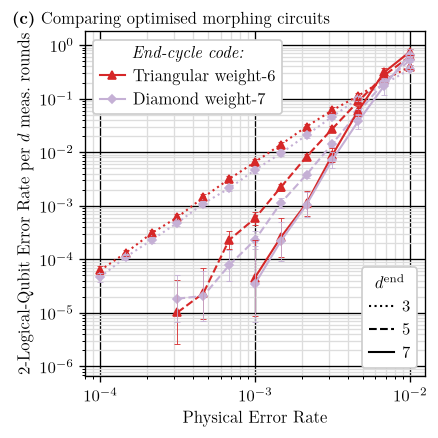

In [11]:
ps = 10**np.linspace(-4,-2,13)
ds = np.array([3, 5, 7])
circuits = ["morphing_extra_qubits", "morphing_rectangular"]
num_copies = {"morphing_extra_qubits": 2,
              "morphing_rectangular": 1,
             }
pls = np.zeros((len(circuits),len(ps),len(ds)))
lbs = np.zeros((len(circuits),len(ps),len(ds)))
ubs = np.zeros((len(circuits),len(ps),len(ds)))

for data_point in raw_data:
    i = np.argmin(np.abs(ps - 10**data_point["log_p"]))
    j = np.argmin(np.abs(ds - data_point["d"]))
    if data_point["label"] in circuits:
        k = circuits.index(data_point["label"])
        pls[k,i,j], lbs[k,i,j], ubs[k,i,j] = shots_to_pl(data_point["flips"], data_point["shots"], num_copies = num_copies[data_point["label"]])


symbols = ['o','s','^','*','v','D']
linestyles = ["-", "--", ":", "-.", (0,(5,1,1,1,1,1))]
sizes = [5/1.2, 4.2/1.2, 6/1.2, 8/1.2, 6/1.2, 4.2/1.2]
legend_sizes = [4,3.5,5.1,6,5.1,3.5]
formal_labels = {"morphing_rectangular": "Diamond weight-7",
                 "morphing_extra_qubits": "Triangular weight-6",
                }
cmap = plt.get_cmap('tab20')
line_colors = {"morphing_rectangular": cmap(9),
          "morphing_extra_qubits": cmap(6),
         }

fig, ax = plt.subplots(1, 1, figsize=(3.41666666667 * target_width/empirical_width,3.478984 * target_width/empirical_width))

ax = plt.gca()
'''
# Get the current color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Rotate the cycle so it starts from the third color
new_colors = [colors[2], colors[5]]
'''
legend1_handles = []
for j in range(len(ds)):
    # Set the new cycle
    ax.set_prop_cycle(cycler(color=new_colors))
    for i in range(len(circuits)):
        symbol_index = [2, 5][i]
        k = {0: 0, 1: 3, 2: 6}[j]# this is just because the first 3 "data points" for the d=7 line are empty
        if j == 2:
            error_bar_container = ax.errorbar(ps[k:], pls[i,k:,j], yerr = [lbs[i,k:,j], ubs[i,k:,j]],
                            linestyle = linestyles[len(ds)-1-j],linewidth = 1.25,
                        color = line_colors[circuits[i]],
                            marker = symbols[symbol_index], ms=sizes[symbol_index],elinewidth=0.5, capthick = 0.5, capsize=2, barsabove = True)
            error_bar_container[0].set_label(formal_labels[circuits[i]])
            legend1_handles.append(error_bar_container[0])
        else:
            ax.errorbar(ps[k:], pls[i,k:,j], yerr = [lbs[i,k:,j], ubs[i,k:,j]],
                            linestyle = linestyles[len(ds)-1-j],linewidth = 1.25,
                        color = line_colors[circuits[i]],
                            marker = symbols[symbol_index], ms=sizes[symbol_index],elinewidth=0.5, capthick = 0.5, capsize=2, barsabove = True)


fig.text(-0.04, 0.897, r'\textbf{(c)} Comparing optimised morphing circuits')

ax.set_ylim(6.57491202030194e-07, 1.8022732185048793)
#ax.set_xlim(0, 700)
ax.set_xscale('log')
ax.set_yscale('log')
#ax.set_title("Colour code memory experiment, SI1000 x=1, MLE")
ax.set_xlabel("Physical Error Rate")
#ax.set_yticklabels([])
ax.set_ylabel(r"2-Logical-Qubit Error Rate per $d$ meas.~rounds")
ax.grid(which='major', color='#000000')
ax.grid(which='minor', color='#DDDDDD')
legend1 = ax.legend(title = r'\textit{End-cycle code:}', handlelength = 1.5, handletextpad = 0.5,
                    handles = legend1_handles, bbox_to_anchor = (0.0,1.0), loc = "upper left", framealpha=1)
ax.add_artist(legend1)
legend2_handles = []
for j in range(len(ds)):
    legend2_handles.append(ax.plot([],[], linestyle = linestyles[len(ds)-1-j],linewidth = 1.25,color = 'k',label=str(ds[j]))[0])
plt.legend(title = r'$d^{\mathrm{end}}$', handlelength = 1.5, handletextpad = 0.5, handles=legend2_handles, loc='lower right', framealpha=1)
fig.set_dpi(120)  # Show it bigger

## Figures 11, 25, and 26

In [12]:
with open("used_data/3B_best_mid_circuit_nkd_params_to_store.pkl", "rb") as f:
    best_mid_circuit_nkd_params = pickle.load(f)
    
with open("used_data/3B_best_morphing_nkd_params_to_store.pkl", "rb") as f:
    best_morphing_nkd_params = pickle.load(f)

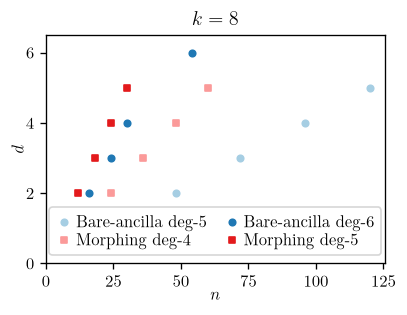

In [13]:
empirical_width = 3.19# set this first to the target_width, check the pdf, then come back with the actual width.
target_width = 3.40

k = 8
cmap = plt.get_cmap('Paired')
mid_cycle_colors = {5: cmap(0), 6: cmap(1)}
end_cycle_colors = {5: cmap(4), 6: cmap(5)}

fig, ax = plt.subplots(1, 1, figsize=(3.41666666667 * target_width/empirical_width,3.478984 * target_width/empirical_width/1.5))
symbols = ['o','s','*','^','X']
sizes = [15, 13.5, 33,22.5, 21]
legend_sizes = [4,3.5,6,5.1,4.5]

for weight in [5,6]:
    x = []
    y = []
    for nkd_param in best_mid_circuit_nkd_params[weight]:
        if nkd_param[1] == k:
            x.append(nkd_param[0])
            y.append(nkd_param[2])
    ax.scatter(x, y, label = f"Bare-ancilla deg-{weight}", marker = symbols[0], s=sizes[0], color = mid_cycle_colors[weight])
    x = []
    y = []
    for nkd_param in best_morphing_nkd_params[weight]:
        if nkd_param[1] == k:
            x.append(nkd_param[0])
            y.append(nkd_param[2])
    ax.scatter(x, y, label = f"Morphing deg-{weight-1}", marker = symbols[1], s=sizes[1], color = end_cycle_colors[weight])

ax.set_ylim(0,6.5)
ax.set_xlim(left = 0)
ax.set_title(r"$k = {}$" + str(k))
ax.set_xlabel(r"$n$", labelpad=-1)
ax.set_ylabel(r"$d$", labelpad=-0.5)
ax.legend(bbox_to_anchor = (0.5,-0.0), loc = "lower center", ncols = 2, handleheight=1, handlelength=1, handletextpad=0.2, columnspacing = 1, labelspacing = 0.1)
fig.set_dpi(120)  # Show it bigger

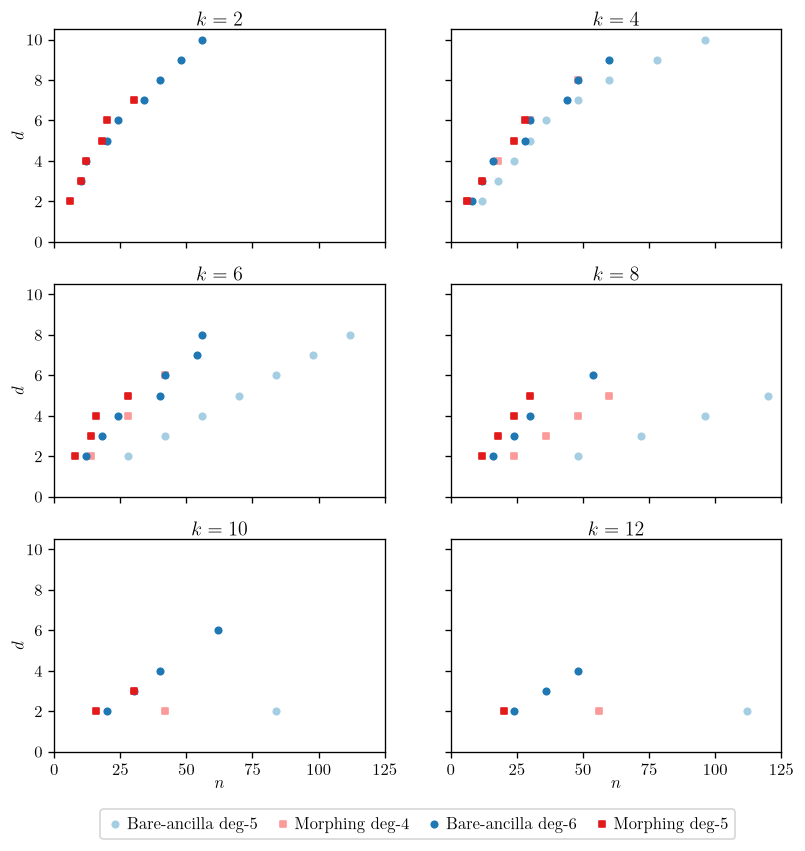

In [14]:
empirical_width = 5.76# set this first to the target_width, check the pdf, then come back with the actual width.
target_width = 6.71

cmap = plt.get_cmap('Paired')
mid_cycle_colors = {5: cmap(0), 6: cmap(1)}
end_cycle_colors = {5: cmap(4), 6: cmap(5)}

fig, ax = plt.subplots(3, 2, figsize=(6.71041666667 * target_width/empirical_width,6.71041666667 * target_width/empirical_width))
symbols = ['o','s','*','^','X']
sizes = [15, 13.5, 33,22.5, 21]
legend_sizes = [4,3.5,6,5.1,4.5]

l = 0
m = 0
for k in range(2,13,2):
    
    for weight in [5,6]:
        x = []
        y = []
        for nkd_param in best_mid_circuit_nkd_params[weight]:
            if nkd_param[1] == k:
                x.append(nkd_param[0])
                y.append(nkd_param[2])
        ax[l,m].scatter(x, y, label = f"Bare-ancilla deg-{weight}", marker = symbols[0], s=sizes[0], color = mid_cycle_colors[weight])
        x = []
        y = []
        for nkd_param in best_morphing_nkd_params[weight]:
            if nkd_param[1] == k:
                x.append(nkd_param[0])
                y.append(nkd_param[2])
        ax[l,m].scatter(x, y, label = f"Morphing deg-{weight-1}", marker = symbols[1], s=sizes[1], color = end_cycle_colors[weight])
    
    
    ax[l,m].set_ylim(0,10.5)
    ax[l,m].set_xlim(0,125)
    ax[l,m].set_title(r"$k = {}$" + str(k), pad = -1)
    if l == 2:
        ax[l,m].set_xlabel(r"$n$", labelpad=-1)
    else:
        ax[l,m].set_xticklabels([])
    if m == 0:
        ax[l,m].set_ylabel(r"$d$", labelpad=-0.5)
        ax[l,m].set_yticks([0,2,4,6,8,10])
    else:
        ax[l,m].set_yticklabels([])
    if l == 2 and m == 1:
        ax[l,m].legend(bbox_to_anchor = (-0.1,-0.45), loc = "lower center", ncols = 4, handleheight=1, handlelength=1, handletextpad=0.2, columnspacing = 1, labelspacing = 0.1)
    m += 1
    if m == 2:
        m = 0
        l += 1
fig.set_dpi(120)  # Show it bigger

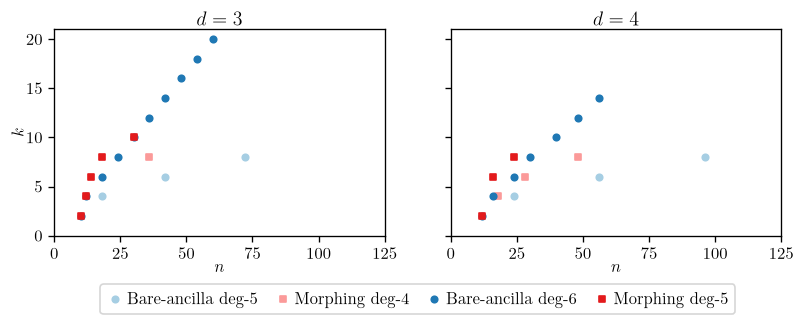

In [15]:
empirical_width = 5.76# set this first to the target_width, check the pdf, then come back with the actual width.
target_width = 6.71

cmap = plt.get_cmap('Paired')
mid_cycle_colors = {5: cmap(0), 6: cmap(1)}
end_cycle_colors = {5: cmap(4), 6: cmap(5)}

fig, ax = plt.subplots(1, 2, figsize=(6.71041666667 * target_width/empirical_width,6.71041666667 * target_width/empirical_width/3.5))
symbols = ['o','s','*','^','X']
sizes = [15, 13.5, 33,22.5, 21]
legend_sizes = [4,3.5,6,5.1,4.5]

l = 0
m = 0
for d in range(3,5):

    for weight in [5,6]:
        x = []
        y = []
        for nkd_param in best_mid_circuit_nkd_params[weight]:
            if nkd_param[2] == d:
                x.append(nkd_param[0])
                y.append(nkd_param[1])
        ax[m].scatter(x, y, label = f"Bare-ancilla deg-{weight}", marker = symbols[0], s=sizes[0], color = mid_cycle_colors[weight])
        x = []
        y = []
        for nkd_param in best_morphing_nkd_params[weight]:
            if nkd_param[2] == d:
                x.append(nkd_param[0])
                y.append(nkd_param[1])
        ax[m].scatter(x, y, label = f"Morphing deg-{weight-1}", marker = symbols[1], s=sizes[1], color = end_cycle_colors[weight])
        
    
    ax[m].set_ylim(0,21)
    ax[m].set_xlim(0,125)
    ax[m].set_title(r"$d = {}$" + str(d), pad = -1)
    if l == 0:
        ax[m].set_xlabel(r"$n$", labelpad=-1)
    else:
        ax[m].set_xticklabels([])
    if m == 0:
        ax[m].set_ylabel(r"$k$", labelpad=-0.5)
        #ax[l,m].set_yticks([0,2,4,6,8,10])
    else:
        ax[m].set_yticklabels([])
    if l == 0 and m == 1:
        ax[m].legend(bbox_to_anchor = (-0.1,-0.42), loc = "lower center", ncols = 4, handleheight=1, handlelength=1, handletextpad=0.2, columnspacing = 1, labelspacing = 0.1)
    m += 1
    if m == 2:
        m = 0
        l += 1
fig.set_dpi(120)  # Show it bigger

### Recovering a mid-cycle code:

In [16]:
from morphing_qec_circuits.code_params import Abelian2BGAParams

In [17]:
with open("used_data/3B_best_mid_circuit_codes_to_store.pkl", "rb") as f:
    best_mid_circuit_codes = pickle.load(f)

In [18]:
stabiliser_weight = 5
nkd_params_to_retrieve = (28,6,2)
my_code = best_mid_circuit_codes[stabiliser_weight][nkd_params_to_retrieve]
my_code

Abelian2BGAParams(group=[14], a_list=[[0], [7]], b_list=[[0], [8], [12]]; lattice_signature=[1, 2], periodicity_vectors=array([[2, 0, 0],
       [0, 7, 0],
       [0, 2, 1]]), n_copies=1; [[n,k,d]]=[[28,6,2]])

### Recovering a morphing circuit:

In [19]:
with open("used_data/3B_best_morphing_circuits_to_store.pkl", "rb") as f:
    best_morphing_circuits = pickle.load(f)

In [20]:
stabiliser_weight = 5
end_cycle_nkd_params_to_retrieve = (14,6,2)

morphing_tuple = best_morphing_circuits[stabiliser_weight][end_cycle_nkd_params_to_retrieve]
mid_cycle_code = morphing_tuple["mid-cycle code"]
morphing_circuit = mid_cycle_code.get_morphing_specifications(*morphing_tuple["morphing_arguments"])

In [21]:
#checking that the morphing circuit has the parameters we expected

morphing_circuit.end_cycle_nkd_params()

Restricted license - for non-production use only - expires 2027-11-29


[(14, 6, 2), (14, 6, 2)]